# El piloto de la cafetería: ¿de dónde sale el +17 %?

**Jornada 3 · Bloque 3.5 · Comparar con criterio**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

cafe = lab.cargar_cafeteria(DATOS)
nombres = cafe["tiendas"].set_index("tienda")["nombre"]
print("Datos listos: ventas diarias de 12 tiendas en 2024 y 2025. Piloto real:",
      ", ".join(nombres[t] for t in lab.PILOTO_REAL))

Datos listos: ventas diarias de 12 tiendas en 2024 y 2025. Piloto real: Campus, Mercado, Hospital, Barrio Alto


## La pregunta

Café Molienda probó su tarjeta de fidelización en cuatro tiendas, «las que más necesitaban un empujón».
Marketing anuncia: «Las ventas de las tiendas piloto se han disparado un 17 %». La tarjeta funciona,
pero no tanto. ¿De dónde sale el resto?

### Cómo está hecho el experimento

En los datos del caso, la tarjeta solo tiene efecto en las cuatro tiendas piloto de verdad (Campus,
Mercado, Hospital y Barrio Alto, desde el 7 de abril de 2025): sube sus ventas un 4,2 %. Para poder
«elegir otras tiendas» sin hacer trampas, el cuaderno hace dos cosas:

1. **Quita el efecto de la tarjeta a las tiendas piloto.** Como los datos son simulados, sabemos cuánto
   es, y así obtenemos cuánto habrían vendido sin tarjeta.
2. **Se lo vuelve a poner a las cuatro tiendas que elijas** si la casilla «La tarjeta funciona» está
   marcada (escenario real: +4,2 %), **o a ninguna** si no lo está (escenario placebo: la tarjeta no hace
   nada).

Con las 4 peores y la tarjeta funcionando salen exactamente los datos y las cifras del caso: +16,7 %
antes y después, +12,8 puntos frente al resto y +5,3 puntos interanual frente al resto. En las demás
combinaciones, la distancia entre cada barra y la línea naranja es el error de cada método: lo que
habríamos medido si el piloto se hubiera hecho en otras tiendas.

Los tres métodos, en cristiano:

- **Antes y después:** ventas por día de las tiendas piloto de abril a junio frente a enero-marzo de 2025.
- **Frente al resto, mismos meses:** lo mismo, restando lo que crecieron las tiendas sin tarjeta.
- **Interanual frente al resto:** de abril a diciembre de 2025 frente al mismo periodo de 2024, piloto
  frente al resto. La línea negra es su intervalo del 95 %.

## El experimento

Elige cómo se escogen las cuatro tiendas piloto y cómo se mide el efecto. Con «4 al azar», pulsa
«Sortear» para otro sorteo. Desmarca «La tarjeta funciona» para ver el escenario placebo.

A la izquierda, las ventas por día del piloto (azul) y del resto (gris), con los dos periodos que compara
el método elegido. A la derecha, lo que mide cada método; la línea naranja es el efecto real.

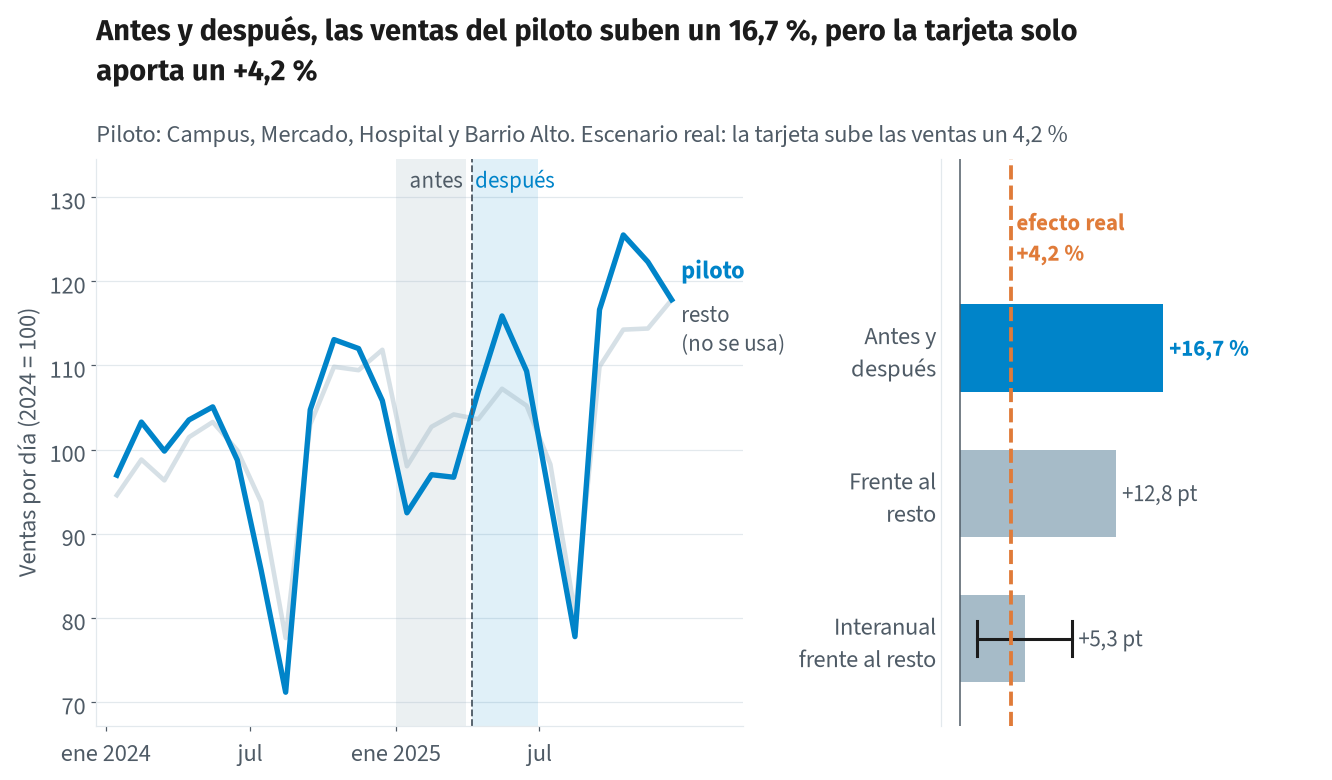

In [2]:
# El experimento: elegir las tiendas y la forma de medir.
seleccion = widgets.ToggleButtons(
    options=[("Las 4 peores del 1.er trimestre", "peores"), ("4 al azar", "azar"),
             ("Las 4 mejores del 1.er trimestre", "mejores")],
    value="peores", description="Tiendas piloto:", style=BOTONES)
sorteo = widgets.IntText(value=0)  # no se ve: lo cambia el botón «Sortear»
sortear = widgets.Button(description="Sortear", icon="random", button_style="info",
                         layout=widgets.Layout(width="auto"))


def nuevo_sorteo(_):
    sorteo.value += 1
    seleccion.value = "azar"


sortear.on_click(nuevo_sorteo)
metodo = widgets.ToggleButtons(
    options=[("Antes y después", "antes_despues"), ("Frente al resto, mismos meses", "frente_resto"),
             ("Interanual frente al resto", "interanual")],
    value="antes_despues", description="Cómo medir:", style=BOTONES)
funciona = widgets.Checkbox(value=True, description="La tarjeta funciona (+4,2 %). Desmárcala para el placebo",
                            style=ESTILO, layout=widgets.Layout(width="600px"))


def dibujar(seleccion, metodo, funciona, sorteo):
    lab.mostrar(lab.dibujar_piloto(cafe, seleccion, metodo, funciona, sorteo))


grafico = widgets.interactive_output(
    dibujar, {"seleccion": seleccion, "metodo": metodo, "funciona": funciona, "sorteo": sorteo})
display(widgets.VBox([widgets.HBox([seleccion, sortear]), metodo, funciona, grafico]))

## Qué observar

1. Con las 4 peores y «antes y después», ¿cuánto del +16,7 % es tarjeta y cuánto otra cosa? ¿Qué otras
   cosas? (Pista: mira enero-marzo en la serie: el invierno es flojo y estas tiendas tuvieron un bache.)
2. Desmarca «La tarjeta funciona». Con las 4 peores, el «antes y después» sigue dando más de un 12 %.
   ¿Cómo crece tanto una tienda con una tarjeta que no hace nada?
3. Elige «4 al azar», método interanual, y sortea varias veces. ¿Cuánto se aleja del efecto real?
   ¿Y el «antes y después»?
4. Con las 4 mejores, «frente al resto» sale muy por debajo del efecto real. ¿Qué tiene que ver la
   regresión a la media?

## Mensaje clave

> **Sin grupo de comparación, todo funciona.**

Y el grupo de comparación tiene que ser comparable: mismo periodo, periodo base normal y, si se puede,
tiendas elegidas al azar.

## Para curiosos

El método «interanual frente al resto» es una versión sencilla de las diferencias en diferencias, que el
avanzado trabaja con datos reales. Con solo cuatro tiendas piloto, su intervalo es ancho
(de +1,4 a +9,2 puntos): para afinar habría que ampliar el piloto.